In [2]:
push!(LOAD_PATH,"./")
push!(LOAD_PATH,"julia/")
include("model.jl")
include("evolution.jl")
using Plots
using DataFrames
using CSV
using StatsPlots

In [3]:
s1 = Strategy(1,0,0,1,1,0,0.5,0,0,0)
s2 = Strategy(1,0,0,1,0.5,0,0,0,2,0)

parameters = Dict("alpha" => 1, "beta" => 4, "lambda" => 1, "b" => 2, "c" => 1, "gamma" => 1, "delta" => 1e-6, "n" => 5)
w1 = solveModel(parameters,s1)
w2 = solveModel(parameters,s2)

f1 = parameters["b"]*w1.meanA - parameters["c"]*w1.meanB
f2 = parameters["b"]*w2.meanA - parameters["c"]*w2.meanB
f1-f2 


0.0

In [5]:
typeof(s1) == Strategy

true

In [30]:
d = Dict{Any, Any}(:rhoB => 0.0, :rhoA => 0.0, :piAA => 0.0, :piBB => 0.0, :thetaAB => 0.0, :thetaBA => 1.0, :piAB => 0.0, :thetaAA => 2.0, :thetaBB => 0.0, :piBA => 0.0)

Dict{Any, Any} with 10 entries:
  :rhoB    => 0.0
  :rhoA    => 0.0
  :piAA    => 0.0
  :piBB    => 0.0
  :thetaAB => 0.0
  :thetaBA => 1.0
  :piAB    => 0.0
  :thetaAA => 2.0
  :thetaBB => 0.0
  :piBA    => 0.0

In [34]:

function reduce_pair(a,b)
    if a > 0 && b > 0
        m = min(a,b)
        a -= m
        b -= m
    end
    return a, b
end
d[:thetaAA],d[:thetaBA] = reduce_pair(d[:thetaAA],d[:thetaBA])

(1.0, 0.0)

In [35]:
d

Dict{Any, Any} with 10 entries:
  :rhoB    => 0.0
  :rhoA    => 0.0
  :piAA    => 0.0
  :piBB    => 0.0
  :thetaAB => 0.0
  :thetaBA => 0.0
  :piAB    => 0.0
  :thetaAA => 1.0
  :thetaBB => 0.0
  :piBA    => 0.0

In [1]:
s = randstruct(Strategy3)
s2 = mutateStrategy(s, 0.5, 0.3)
s2.piBXY + s2.piBXZ

UndefVarError: UndefVarError: `randstruct` not defined

In [5]:

Strategy(pi::Vector{Float64},
         theta::Vector{Float64},
         rho::Vector{Float64}) = begin

    length(pi) == 4 || error("pi must have length 3")
    length(theta) == 4 || error("theta must have length 3")
    length(rho) == 2 || error("rho must have length 3")

    Strategy(
        pi[1], pi[2], pi[3], pi[4],
        theta[1], theta[2], theta[3], theta[4],
        rho[1], rho[2]
    )
end

Strategy

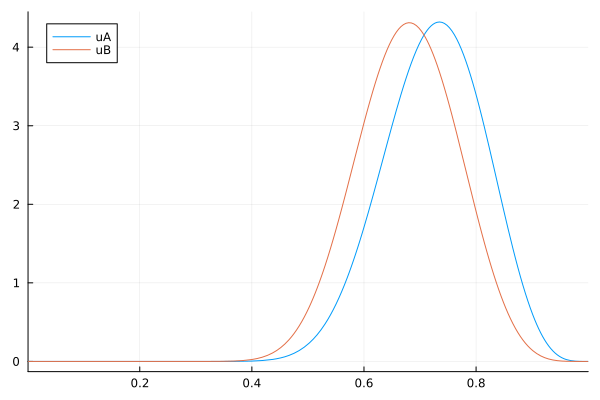

In [6]:
parameters = Dict("alpha" => 1.0, "beta" => 1.0, "gamma" => 1.0, "delta" => 1e-6, "lambda" => 10.0, "b" => 2.0, "c" => 1.0, "n" => 0)
pi = [1.0, 0.0, 0.0, 1.0]
theta = [1.0, 0.0, 0.0, 0.0]
rho = [0.0, 0.0]
s = Strategy(pi, theta, rho)
sol = solveModel(parameters,s)
plot([sol.uA sol.uB], xlim=sol.I, label=["uA" "uB"])

In [49]:
getproperty(s1, Symbol("piAA"))

0.9249772598160287

In [15]:
function run_sim()
    s = Strategy(0,0,0,0,0,0,0,0,0,0)
    parameters = Dict("alpha" => 4.0, "beta" => 10.0, "gamma" => 0.0, "delta" => 1e-6, "lambda" => 1.0, "b" => 2.0, "c" => 1.0, "n" => 0)
    fitnessFunction = x -> fitness(parameters, x)
    mutationFunction = x -> mutateStrategy(x, 0.1, 0.3; mutate_rho=false)
    sim = evolutionarySimulation(s, fitnessFunction, strongSelectionFixationProbability, mutationFunction, 1e3, verbose=false)[1]
end

results = [run_sim() for _ in 1:100]


15 mutants fixed
26 mutants fixed
26 mutants fixed
17 mutants fixed
20 mutants fixed
25 mutants fixed
17 mutants fixed
25 mutants fixed
28 mutants fixed
21 mutants fixed
28 mutants fixed
36 mutants fixed
25 mutants fixed
24 mutants fixed
17 mutants fixed
37 mutants fixed
18 mutants fixed
30 mutants fixed
32 mutants fixed
21 mutants fixed
41 mutants fixed
26 mutants fixed
23 mutants fixed
24 mutants fixed
31 mutants fixed
28 mutants fixed
12 mutants fixed
20 mutants fixed
25 mutants fixed
30 mutants fixed
24 mutants fixed
23 mutants fixed
26 mutants fixed
23 mutants fixed
25 mutants fixed
40 mutants fixed
29 mutants fixed
21 mutants fixed
26 mutants fixed
29 mutants fixed
17 mutants fixed
23 mutants fixed
22 mutants fixed
27 mutants fixed
20 mutants fixed
23 mutants fixed
23 mutants fixed
27 mutants fixed
26 mutants fixed
28 mutants fixed
33 mutants fixed
23 mutants fixed
19 mutants fixed
16 mutants fixed
17 mutants fixed
17 mutants fixed
22 mutants fixed
20 mutants fixed
19 mutants fix

100-element Vector{Strategy}:
 Strategy(1.0, 0.0, 0.0, 1.0, 0.17475754267021207, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.2959748430690531, 0.0, 0.0, 0.0867755741902213, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.20276655366085658, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.267019851586892, 0.0, 0.0, 0.057436842906292127, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.21160636045106607, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.20288463187425926, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.43875640915802944, 0.0, 0.0, 0.2356603040545683, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.180019240892472, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.2048467334807199, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.20513328293775734, 0.0, 0.0, 0.0, 0.0, 0.0)
 ⋮
 Strategy(1.0, 0.0, 0.0, 1.0, 0.19841777810650135, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 0.0, 0.0, 1.0, 0.2103136839117495, 0.0, 0.0, 0.0, 0.0, 0.0)
 Strategy(1.0, 

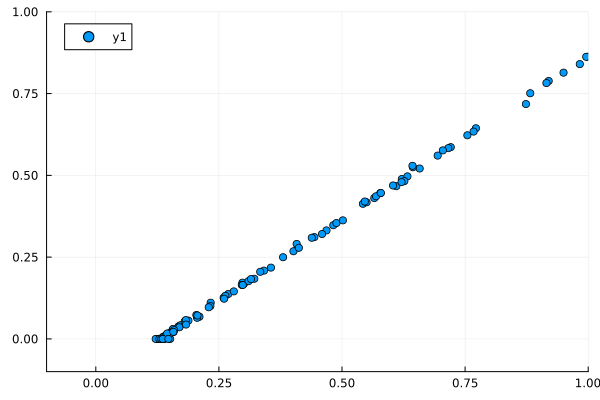

In [11]:
using Plots
scatter([x.thetaAA for x in results],[x.thetaBB for x in results],xlims=(-0.1,1),ylims=(-0.1,1))

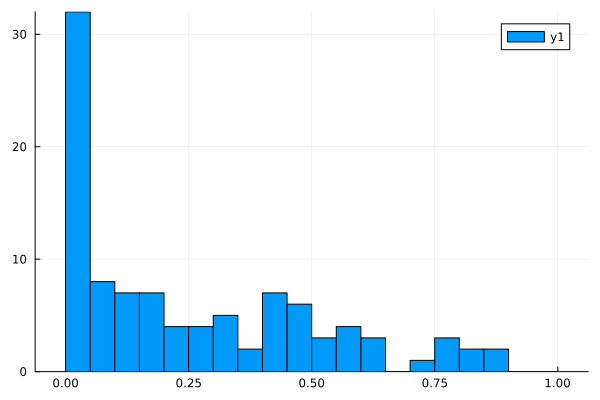

In [24]:
histogram([x.thetaBB for x in results],bins=0:0.05:1)

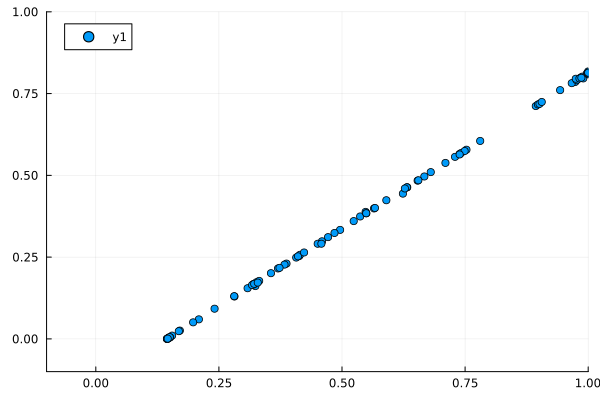

In [16]:
using Plots
scatter([x.thetaAA for x in results_finite],[x.thetaBB for x in results_finite],xlims=(-0.1,1),ylims=(-0.1,1))

In [4]:
sim[1]

Strategy(1.0, 0.0, 0.0, 1.0, 0.36755897116507613, 0.0, 0.0, 0.23483004028257054)

In [4]:
s = Strategy(0,0,0,0,0,0,0,0)
fitnessFunction = x -> fitness(0, 4.2, 4, 1e-6, 1, x, 5, 1)[1]
#fitnessFunction = x -> fitnessFiniteModel(5, 3, 1, 1e-6, 1, x, 4, 1)
mutationFunction = x -> mutateStrategy(x, 0.1, 0.3)
sim = evolutionarySimulation(s, fitnessFunction, strongSelectionFixationProbability, mutationFunction, 1e4)

The initial fitness is 0.9999999999999998
After 4 mutants failed, Strategy(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0) fixed with fitness = 1.0 and fixation probability 1
After 4 mutants failed, Strategy(0.0, 0.0, 0.0, 0.1500506580618827, 0.0, 0.0, 0.0, 0.0) fixed with fitness = 1.6371468805710916 and fixation probability 1
After 2 mutants failed, Strategy(0.270952905384601, 0.0, 0.0, 0.1500506580618827, 0.0, 0.0, 0.0, 0.0) fixed with fitness = 1.750836575878305 and fixation probability 1
After 2 mutants failed, Strategy(0.270952905384601, 0.0, 0.0, 0.07515559892297026, 0.0, 0.0, 0.0, 0.0) fixed with fitness = 1.7911246854943448 and fixation probability 1
After 0 mutants failed, Strategy(0.270952905384601, 0.0, 0.038940440485192296, 0.07515559892297026, 0.0, 0.0, 0.0, 0.0) fixed with fitness = 1.9287144467556054 and fixation probability 1
After 6 mutants failed, Strategy(0.270952905384601, 0.0, 0.038940440485192296, 0.07515559892297026, 0.19316425656125688, 0.0, 0.0, 0.0) fixed with fitnes

(Strategy(1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.043040210230554626, 0.0), 2.1145087042707913)

In [6]:
s = Strategy(1,0,0,1,1,0,0,0)
fitness(0,4.2,4,1e-6,1,s,5,1)

(2.1141825615772456, [0.9048611211486991, 0.2959404825890046])

In [14]:
s = Strategy(0,0,0,0,0,0,0,0)
fitnessFunction = x -> fitness(5, 3, 1, 1e-6, 1, x, 4, 1)[1]
#fitnessFunction = x -> fitnessFiniteModel(5, 3, 1, 1e-6, 1, x, 4, 1)
mutationFunction = x -> mutateStrategy(x, 0.1, 0.3)
sim = evolutionarySimulation(s, fitnessFunction, strongSelectionFixationProbability, mutationFunction, 1e4)

The initial fitness is 0.7499999999918905
After 9 mutants failed, Strategy(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0) fixed with fitness = 1.2499914984360765 and fixation probability 1
After 0 mutants failed, Strategy(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2744522574212631, 0.0) fixed with fitness = 1.4999953524005023 and fixation probability 1
After 8 mutants failed, Strategy(0.19426331090556107, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2744522574212631, 0.0) fixed with fitness = 1.4999969412147272 and fixation probability 1
After 10 mutants failed, Strategy(0.19426331090556107, 0.0, 0.0, 0.0, 0.1358556867805687, 0.0, 0.2744522574212631, 0.0) fixed with fitness = 1.4999981775283717 and fixation probability 1
After 2 mutants failed, Strategy(0.19426331090556107, 0.0, 0.3465695671500855, 0.0, 0.1358556867805687, 0.0, 0.2744522574212631, 0.0) fixed with fitness = 1.4999982972254202 and fixation probability 1
After 2 mutants failed, Strategy(0.19426331090556107, 0.0, 0.3465695671500855, 0.0, 0.19845252253204748,

(Strategy(1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0), 1.562499697916783)

In [15]:
sim

(Strategy(1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0), 1.562499697916783)

In [3]:
string(s)

"Strategy(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)"

In [2]:

alpha = collect(1:1:6)
beta = collect(1:1:6)
yA = [4.0]
yB = [1.0]
lambda = [1.0]

d = DataFrame(collect(Iterators.product(alpha,beta,yA,yB,lambda)))
rename!(d,[:alpha,:beta,:yA,:yB,:lambda])

pars = [:piAA, :piAB, :piBA, :piBB, :thetaAA, :thetaAB, :thetaBA, :thetaBB]
for p in pars
    d[:,p] = [0.0 for _ in 1:nrow(d)]
end
d.fitness = [-1.0 for _ in 1:nrow(d)]

for i in 1:nrow(d)
    println(i)
    s = Strategy(0,0,0,0,0,0,0,0)

    sim = evolutionarySimulation(s, x -> fitnessInfiniteModel(d.alpha[i], d.beta[i], d.lambda[i], x, d.yA[i], d.yB[i]), 
            strongSelectionFixationProbability, x -> mutateStrategy(x, 0.1, 0.3), 1000)

    d.fitness[i] = sim[2]
    for p in pars
        d[i,p] = getproperty(sim[1],p)
    end
end

CSV.write("results.csv",d)

1
The initial fitness is 1.25
After 1 mutants failed, a mutant fixed with fitness = 2.0 and fixation probability 1
After 609 mutants failed, a mutant fixed with fitness = 2.0000000000000004 and fixation probability 1
After 11 mutants failed, a mutant fixed with fitness = 2.0000000000000013 and fixation probability 1
3 mutants fixed
2
The initial fitness is 1.25
After 2 mutants failed, a mutant fixed with fitness = 2.0 and fixation probability 1
After 506 mutants failed, a mutant fixed with fitness = 2.0000000000000004 and fixation probability 1
After 48 mutants failed, a mutant fixed with fitness = 2.000000000000001 and fixation probability 1
After 93 mutants failed, a mutant fixed with fitness = 2.0000000000000018 and fixation probability 1
4 mutants fixed
3
The initial fitness is 1.25
After 0 mutants failed, a mutant fixed with fitness = 2.0 and fixation probability 1
After 367 mutants failed, a mutant fixed with fitness = 2.0000000000000004 and fixation probability 1
After 487 mutan

"results.csv"

In [58]:
alpha = 5
beta = 4
lambda = 1
gamma = 1e-6
yA = 1.5
w1 = evolutionarySimulation(Strategy(0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0),
s->fitnessFiniteModel(5,alpha,beta,gamma,lambda,s,yA,1.0),strongSelectionFixationProbability,mutateStrategy,1e4,verbose=false)
w2 = evolutionarySimulation(Strategy(0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0),s->fitnessInfiniteModel(alpha,beta,lambda,s,yA,1.0),
strongSelectionFixationProbability,mutateStrategy,1e4,verbose=false)
[w1; w2]

38 mutants fixed
26 mutants fixed


2-element Vector{Tuple{Strategy, Float64}}:
 (Strategy(1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.5695605601983551), 1.074097150103212)
 (Strategy(1.0, 0.0, 0.0, 1.0, 0.4959419675444512, 0.0, 0.0, 0.1669797383749848), 1.0737873315886093)

The initial fitness is 0.525
After 0 mutants failed, a mutant fixed with fitness = 0.55 and fixation probability 1
After 25 mutants failed, a mutant fixed with fitness = 0.5738050340890463 and fixation probability 1
After 2 mutants failed, a mutant fixed with fitness = 0.5747022486646856 and fixation probability 1
After 5 mutants failed, a mutant fixed with fitness = 0.5884758706358291 and fixation probability 1
After 3 mutants failed, a mutant fixed with fitness = 0.6431682968357821 and fixation probability 1
After 0 mutants failed, a mutant fixed with fitness = 0.6837804577478357 and fixation probability 1
After 2 mutants failed, a mutant fixed with fitness = 0.7028575912308344 and fixation probability 1
After 0 mutants failed, a mutant fixed with fitness = 0.7509907694827164 and fixation probability 1
After 2 mutants failed, a mutant fixed with fitness = 0.7539616429951836 and fixation probability 1
After 2 mutants failed, a mutant fixed with fitness = 0.8147474507816206 and fixatio

(Strategy(1.0, 0.0, 0.0, 1.0, 0.773325930541782, 0.0, 0.0, 0.0), 0.9001104950409393)

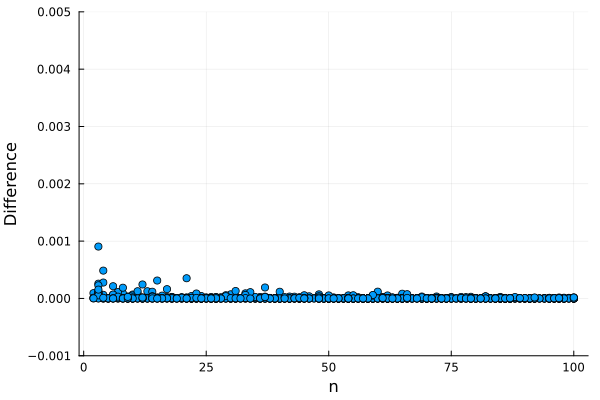

In [3]:
using DataFrames
using Plots
d = DataFrame(alpha = [], beta = [], gamma = [], n = [], piAA = [], piAB = [], piBA = [], piBB = [], thetaAA = [], thetaAB = [], thetaBA = [], thetaBB =[], rhoA=[], rhoB=[], f1=[], f2=[])
for i in 1:1000
    s = Strategy(rand(),rand(),rand(),rand(),rand(),rand(),rand(),rand(),rand(),rand())
    alpha = rand()*50
    beta = rand()*5
    gamma = rand()*2
    lambda = 1
    delta = 0
    yA = 1
    yB = 1
    n = rand(2:100)
    f1 = fitnessInfiniteModel(alpha,beta,gamma,lambda,s,yA,yB)
    f2 = fitnessFiniteModel(n,alpha,beta,gamma,delta,lambda,s,yA,yB)
    if abs(f1-f2) > 0.01
        println(n)
    end
    push!(d, (alpha=alpha, beta=beta, gamma=gamma, n =n, piAA = s.piAA, piAB = s.piAB, piBA= s.piBA, piBB=s.piBB, thetaAA=s.thetaAA,thetaAB=s.thetaAB, thetaBA=s.thetaBA, thetaBB=s.thetaBB, rhoA=s.rhoA, rhoB=s.rhoB, f1=f1, f2=f2))
end
scatter(d.n,abs.(d.f1-d.f2),ylims=(-0.001,0.005),label="",xlab="n",ylab="Difference")

In [76]:
f1

0.49706802333601807

In [85]:
minimum(f1s .- f2s)

-0.018261196508140676

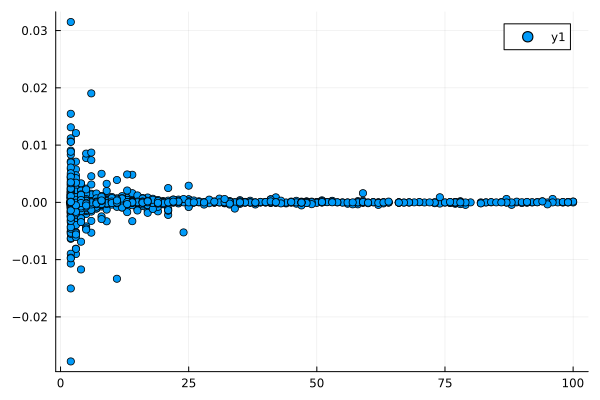

In [69]:
floor(100^rand())

46.0

In [40]:
vcat([0,1,2,3,4],[4,3,2,1,0])

10-element Vector{Int64}:
 0
 1
 2
 3
 4
 4
 3
 2
 1
 0

In [37]:
(0:n) .* yB

0:1:4